In [1]:
%load_ext autoreload
%autoreload 2
import os
import sys
sys.path.append(os.path.abspath('../../espaloma-charge_mod/'))
sys.path.append(os.path.abspath('../'))
import ResParTools as pt
from espaloma_charge import charge
from rdkit import Chem
from rdkit.Chem.Draw import IPythonConsole
IPythonConsole.ipython_useSVG = True

# Расчёт зарядов модифицированного остатка - версия без словарей

Тот же протокол, что в `1_charge_calculation.ipynb`, но все данные хранятся **в самой молекуле RDKit**
(схема - `docs/MOL_PROPS.md`):

| Свойство | у чего | шаг | что значит |
|---|---|---|---|
| `ModName`, `SourceFile` | молекула | 1 | имя и файл исходной молекулы |
| `SrcIdx` | атом | 1 | индекс атома в исходном файле |
| `PolymerIdx` | атом | 2 | индекс атома в тримере |
| `PrevIdx`, `ParentName` | атом | 3 | индекс до перенумерации; имя атома в родительском остатке (у новых атомов свойства нет) |
| `Parent`, `RefResidue`, `Naming` | молекула | 3 | родитель, его шаблон, способ имён |
| `AtomName` | атом | 3-4 | имя атома в остатке |
| `AddedH` | атом | 4.1 | водород, добавленный только для acpype |
| `Charge<Метод>`, `ChargeFixed` | атом | 5-6 | заряды каждого метода (`ChargeEspaloma`, `ChargeRESP`, ...), фиксированные атомы остова |
| `ChargeMethod` | молекула | 5-6 | метод, чьи заряды пойдут в силовое поле |

Между шагами молекула сохраняется одним файлом: `pt.save_mol` / `pt.load_mol` (SDF со всеми свойствами).
Функции, которые раньше возвращали словари (`file_opener`, `match_mon_to_pol`), здесь заменены на
`pt.open_mol` и `pt.find_residue` - они возвращают одну молекулу.

In [2]:
# Параметры модификации
PTM_name = 'C_AF546'
base_name = '546'
parent_residue = 'C'
monomer_file = 'molecules/C_AF_546.smiles'
trimer_file = 'molecules/ACA_AF_546.smiles'
naming = 'index'
resp_run = 'slurm'
run_resp_now = False          # True - запустить RESP в этом ноутбуке (долго: около часа на лизин)
# куда писать результаты (вне git; окончательное место - обсуждается)
OUT = os.path.join('..', 'build', 'props', os.path.basename(os.getcwd()))
os.makedirs(OUT, exist_ok=True)

## Шаг 1. Мономер и тример
`pt.open_mol` - одна молекула; у атомов `SrcIdx`, у молекулы `ModName`, `SourceFile`.

In [3]:
monomer = pt.open_mol(monomer_file)
trimer = pt.open_mol(trimer_file)
mon_name = monomer.GetProp('ModName')
print(mon_name, monomer.GetNumAtoms(), '|', trimer.GetProp('ModName'), trimer.GetNumAtoms())

Загрузка файла: C_AF_546 (формат: .smiles)
Загрузка файла: ACA_AF_546 (формат: .smiles)
C_AF_546 125 | ACA_AF_546 147


## Шаг 2. Остаток внутри тримера
`pt.find_residue` возвращает остаток (атомы мономера); у каждого атома - `PolymerIdx`, его индекс в тримере.

Выполнение Поиск подструктуры между молекулами.  

Выполнение Поиск подструктуры между молекулами.. 

Выполнение Поиск подструктуры между молекулами...

Выполнение Поиск подструктуры между молекулами.  

Выполнение Поиск подструктуры между молекулами.. 

...

Выполнение Поиск подструктуры между молекулами.. 

Выполнение Поиск подструктуры между молекулами...

Выполнение Поиск подструктуры между молекулами.  

Выполнение Поиск подструктуры между молекулами.. 


Поиск подструктуры между молекулами выполнен успешно!
⚠ MCS остановлен по timeout, подструктура может быть неполной


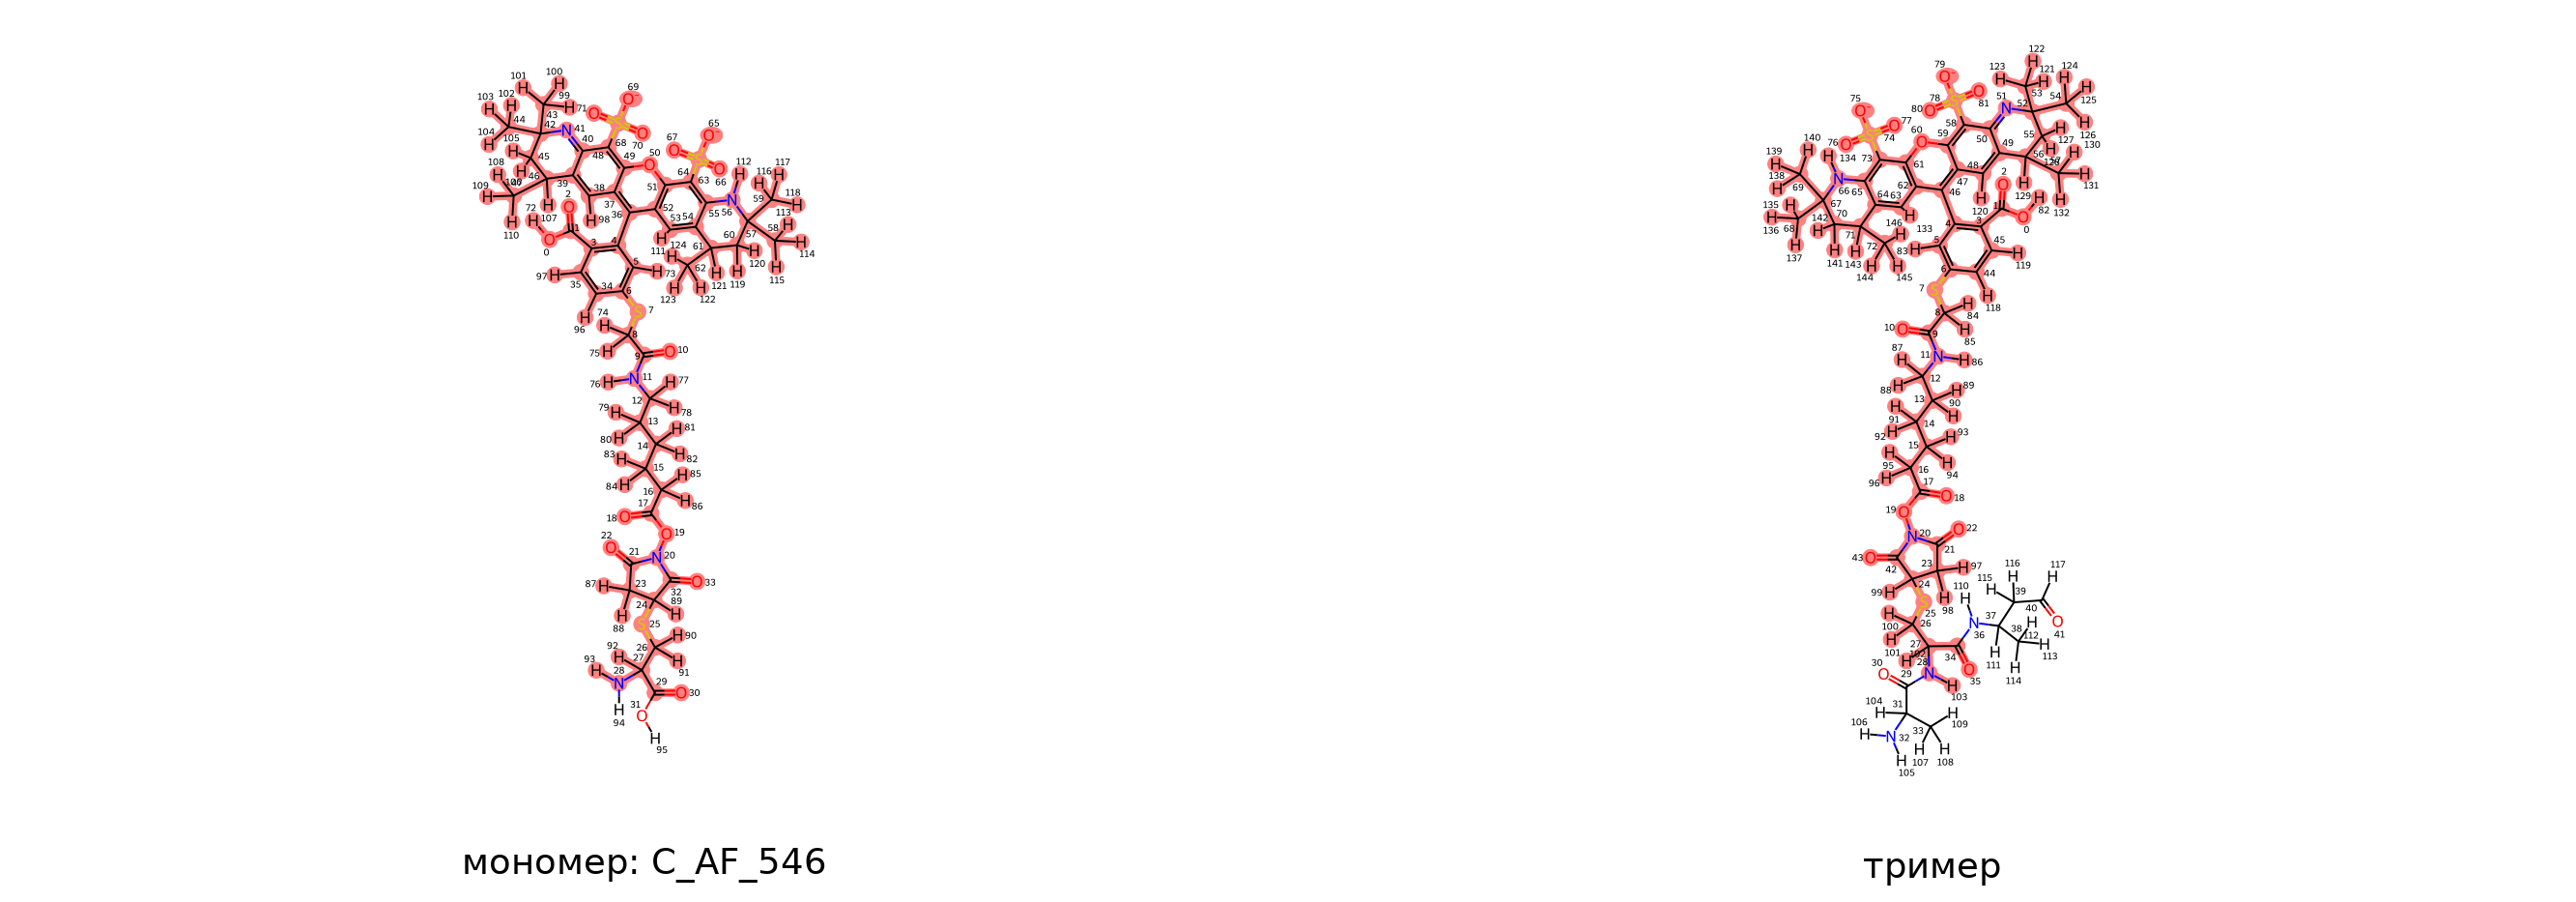

In [4]:
residue = pt.find_residue(monomer, trimer, timeout=5)
in_trimer = [a.GetIntProp('PolymerIdx') for a in residue.GetAtoms()]
in_monomer = [a.GetIntProp('SrcIdx') for a in residue.GetAtoms()]
pt.draw_mol_grid([monomer, trimer], legends=[f'мономер: {mon_name}', 'тример'],
                 highlight_atoms=[in_monomer, in_trimer])

## Шаг 3. Перенумерация и имена атомов
Атомы родительского остатка получают `ParentName`; список `parent_atoms` больше не хранится - он вычисляется из свойств.

Выполнение Поиск подструктуры между молекулами.  


Поиск подструктуры между молекулами выполнен успешно!
Родительский остаток: цистеин (Cys, C), шаблон GCG_H; сопоставлено атомов: 10.
Перенумеровано атомов: 122 из 122 (канонических: 10)
Имена атомов (способ 'index'): родительский остаток - N H CA HA CB HB1 HB2 SG C O; остальные 112 атомов - элемент + индекс.


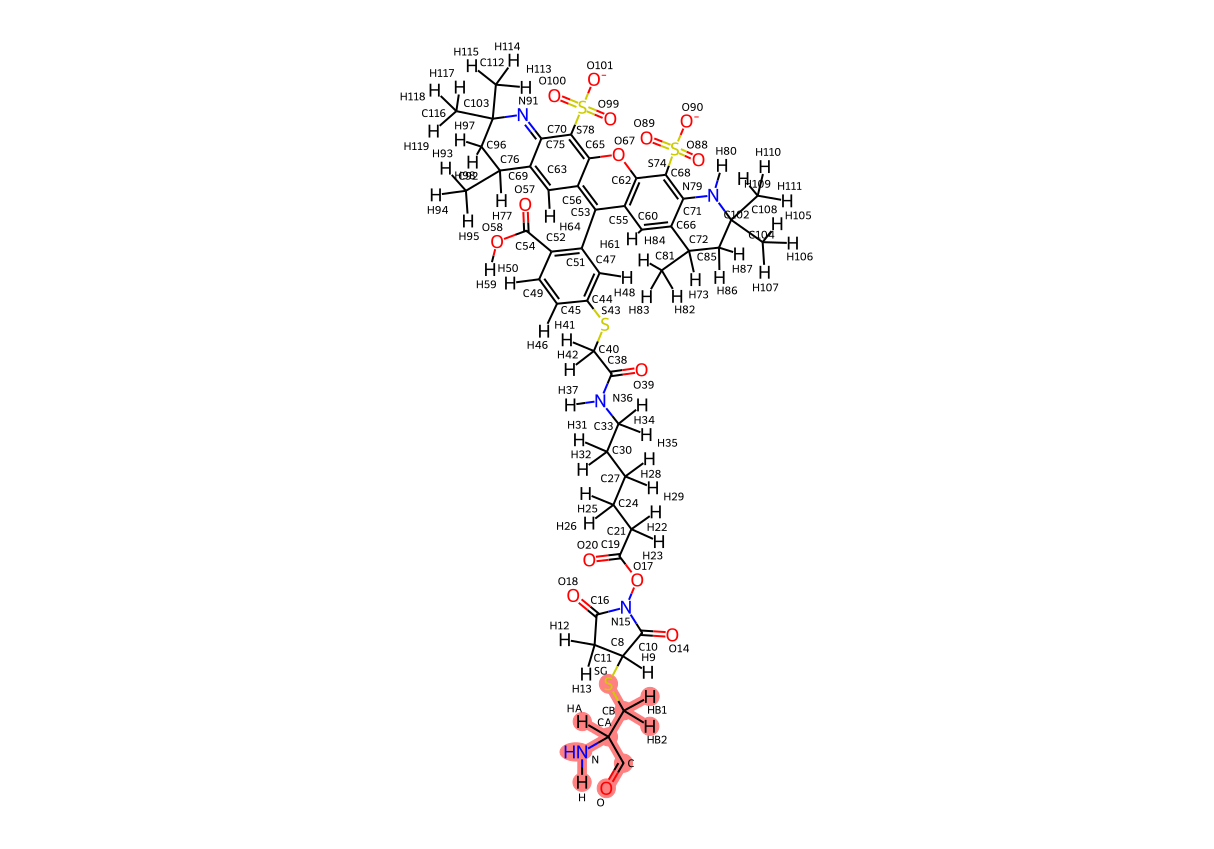

In [5]:
residue = pt.renumber_residue_atoms(residue, ref_base_name=parent_residue, timeout=5)
parent_atoms = [a.GetIdx() for a in residue.GetAtoms() if a.HasProp('ParentName')]
residue = pt.rdkit_pdb_modification(residue, resname=base_name, resid=2, segid='A',
                                    naming=naming, parent_atoms=parent_atoms)
pt.draw_molecule(residue, highlight_atoms=parent_atoms, show_names=True, show_index=False)

## Шаг 4. Правка имён, проверка дубликатов
`rename_map = {'старое имя': 'новое имя'}`; пустой - имена не меняются.

In [6]:
rename_map = {}
residue = pt.modifie_residue_info(residue, rename_map, resname=base_name, resid=2, segid='A')
duplicates = pt.check_duplicate_atom_names(residue)
if duplicates:
    raise ValueError(f'Повторяющиеся имена атомов (имя: индексы): {duplicates}')

Дубликаты имен атомов не найдены.


In [7]:
# таблица атомов: всё, что известно об атоме, - в его свойствах
for a in residue.GetAtoms():
    print(f"{a.GetIdx():3d} {a.GetProp('AtomName'):5s} родитель: {a.GetProp('ParentName') if a.HasProp('ParentName') else '-':5s} "
          f"исходный индекс: {a.GetIntProp('SrcIdx'):3d} в тримере: {a.GetIntProp('PolymerIdx'):3d}")

  0 N     родитель: N     исходный индекс:  28 в тримере:  28
  1 H     родитель: H     исходный индекс:  93 в тримере: 103
  2 CA    родитель: CA    исходный индекс:  27 в тримере:  27
  3 HA    родитель: HA    исходный индекс:  92 в тримере: 102
  4 CB    родитель: CB    исходный индекс:  26 в тримере:  26
  5 HB1   родитель: HB1   исходный индекс:  90 в тримере: 100
  6 HB2   родитель: HB2   исходный индекс:  91 в тримере: 101
  7 SG    родитель: SG    исходный индекс:  25 в тримере:  25
  8 C8    родитель: -     исходный индекс:  24 в тримере:  24
  9 H9    родитель: -     исходный индекс:  89 в тримере:  99
 10 C10   родитель: -     исходный индекс:  32 в тримере:  42
 11 C11   родитель: -     исходный индекс:  23 в тримере:  23
 12 H12   родитель: -     исходный индекс:  87 в тримере:  97
 13 H13   родитель: -     исходный индекс:  88 в тримере:  98
 14 O14   родитель: -     исходный индекс:  33 в тримере:  43
 15 N15   родитель: -     исходный индекс:  20 в тримере:  20
 16 C16 

### Шаг 4.1. Водороды для acpype
Добавленные водороды помечены свойством атома `AddedH` (на шаге 3 силового поля удаляются по нему, а не по имени).

Добавлены водороды (имя - атом): HW1 - N (0), HW2 - C (120)


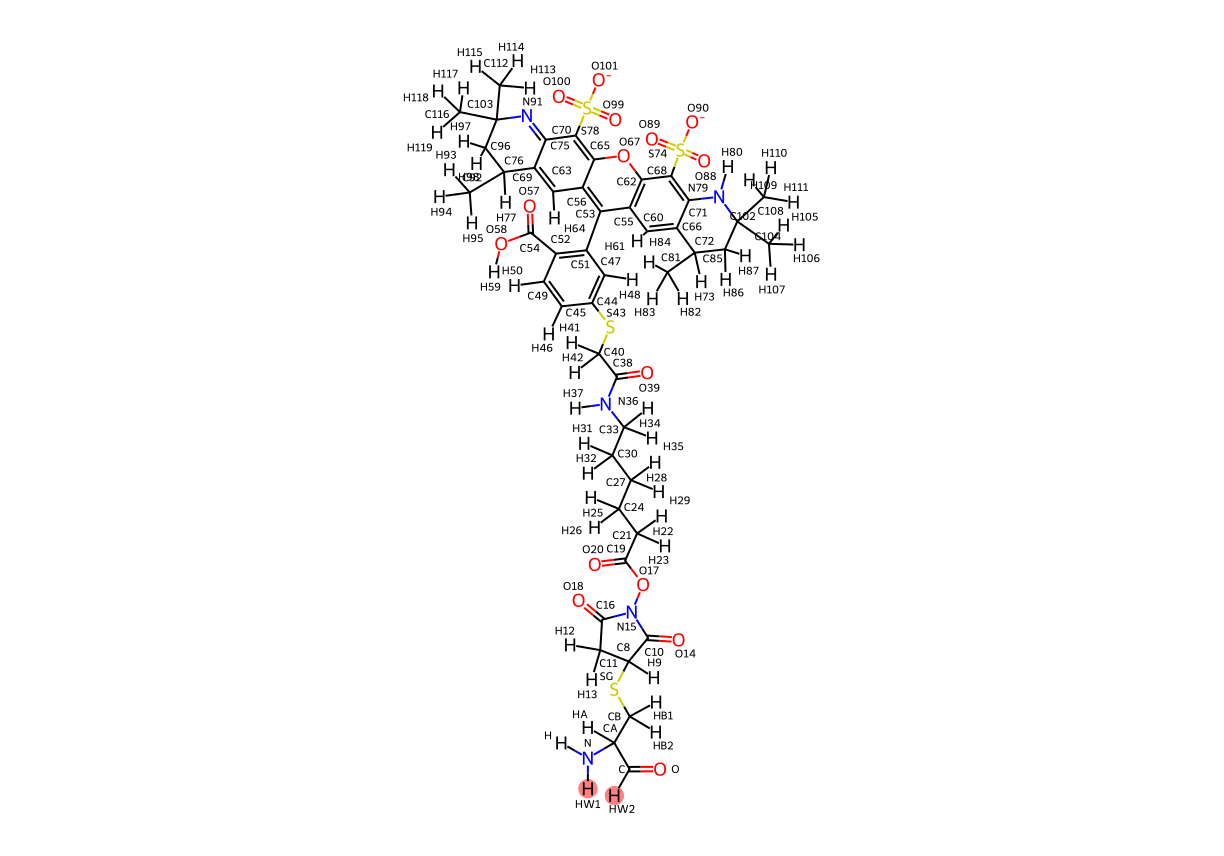

In [8]:
h_residue = pt.add_protons_and_renumber_H(residue, resname=base_name, resid=2, segid='A')
added = [a.GetIdx() for a in h_residue.GetAtoms() if a.HasProp('AddedH') and a.GetBoolProp('AddedH')]
pt.draw_molecule(h_residue, highlight_atoms=added, show_names=True, show_index=False)

## Шаг 5. Заряды Espaloma
Заряды записываются в атомы: `ChargeEspaloma`; фиксированные атомы остова - `ChargeFixed`.

Заряды из CYS (имя, индекс, заряд): N 0 -0.4157, H 1 +0.2719, CA 2 +0.0213, HA 3 +0.1124, C 120 +0.5973, O 121 -0.5679
сумма зарядов: -2.00000 (заряд остатка -2)


/home/nikolay/anaconda3/envs/darwin_ec/lib/python3.12/site-packages/dgl/heterograph.py:92: DGLWarning: Recommend creating graphs by `dgl.graph(data)` instead of `dgl.DGLGraph(data)`.
  dgl_warning(


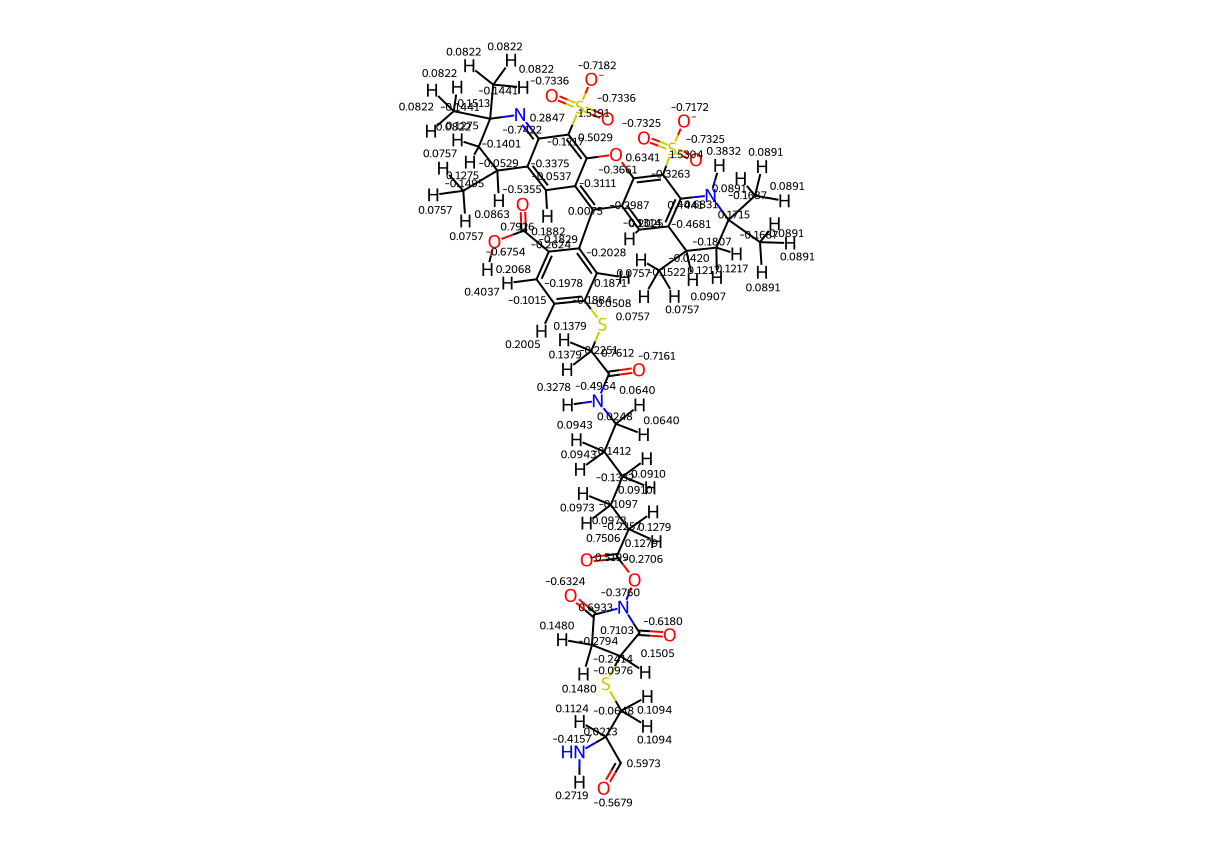

In [9]:
constraints = pt.charge_constraints_from_rtp(residue, pt.AMINO_ACIDS[parent_residue][0].upper())
q = charge(residue, constraints=constraints)
pt.set_charges(residue, q, 'Espaloma', constraints)
total = Chem.GetFormalCharge(residue)
print(f'сумма зарядов: {q.sum():.5f} (заряд остатка {total})')
if abs(q.sum() - total) > 1e-3:
    raise ValueError('Сумма зарядов не равна заряду остатка.')
pt.draw_molecule(residue, charge_list=q, show_names=False, show_index=False)

## Шаг 6. RESP (по желанию)
Задача готовится в `OUT/resp`; считать - `run_resp_now = True` или на кластере. Готовые заряды - в `ChargeRESP`.

In [10]:
resp_folder = pt.prepare_resp_job(residue, constraints, f'{mon_name}_capped', working_dir=os.path.join(OUT, 'resp'),
                                  fix_backbone=True, n_sidechain=3, monomer=monomer)
if run_resp_now:
    pt.run_resp(resp_folder, run=resp_run, n_threads=4, n_parallel=1)
# готовый результат: этой задачи или ночного расчёта (build/resp/<папка>/)
done = [f for f in (resp_folder, os.path.join('..', 'build', 'resp', os.path.basename(os.getcwd()), f'{mon_name}_capped'))
        if os.path.exists(os.path.join(f, 'result.json'))]
if done:
    pt.set_charges(residue, pt.load_resp_result(done[0]), 'RESP', constraints)
    pt.compare_charges(residue, {m: [a.GetDoubleProp(f'Charge{m}') for a in residue.GetAtoms()]
                                 for m in ('Espaloma', 'RESP')})
residue.SetProp('ChargeMethod', 'Espaloma')   # заряды для силового поля

3D-структура, стереоцентры: CA (27) - L (R по CIP); по умолчанию R: [24, 45, 60]


alphaR: все конформации в окне 10.0 ккал/моль свёрнуты (контакт боковой цепи с остовом); взяты конформации без контакта, самая низкая - на 32.7 ккал/моль выше минимума MMFF (газовая фаза).


beta: все конформации в окне 10.0 ккал/моль свёрнуты (контакт боковой цепи с остовом); взяты конформации без контакта, самая низкая - на 13.0 ккал/моль выше минимума MMFF (газовая фаза).
⚠ beta: в окне 10.0 ккал/моль 2 конформаций из нужных 3; добавляются следующие по энергии.
Конформации RESP (00:54:58): alphaR_1 (phi -60.0, psi -40.0, dE 32.71); alphaR_2 (phi -60.0, psi -40.0, dE 42.25); alphaR_3 (phi -60.0, psi -40.0, dE 34.32); beta_1 (phi -120.0, psi 130.0, dE 13.02); beta_2 (phi -120.0, psi 130.0, dE 23.59); beta_3 (phi -120.0, psi 130.0, dE 17.34)
Стереохимия конформаций проверена: центров 4 (R/S), двойных связей 0 (E/Z) - как задано, CA - L
Задача RESP: /home/nikolay/Documents/VS_code/ResParTools/notebooks_and_examples/build/props/AF_546_cys/resp/C_AF_546_capped | молекула 134 атомов (заряд -2, capped), остаток 122 атомов (заряд -2), фиксировано зарядов 18, групп эквивалентных атомов 18, конформаций 6


## Сохранение
Один файл SDF со всеми свойствами (`pt.load_mol` читает его обратно) и 3D PDB для acpype.

In [11]:
path = pt.save_mol(residue, os.path.join(OUT, f'4_{mon_name}'))
pt.save_mol(h_residue, os.path.join(OUT, f'4_1_{mon_name}'))
pt.save_chem_to_pdb(h_residue, os.path.join(OUT, f'{PTM_name}_rn_H_3D'), coords='3D')
back = pt.load_mol(path)
print('свойства молекулы:', back.GetPropsAsDict())
print('свойства атома 0:', back.GetAtomWithIdx(0).GetPropsAsDict())

3D-структура, стереоцентры: CA (2) - L (R по CIP); по умолчанию R: [8, 72, 76]
свойства молекулы: {'ModName': 'C_AF_546', 'SourceFile': 'molecules/C_AF_546.smiles', 'Parent': 'C', 'RefResidue': 'GCG_H', 'OldIndices': '[28, 92, 27, 91, 26, 89, 90, 25, 24, 88, 31, 23, 86, 87, 32, 20, 21, 19, 22, 17, 18, 16, 84, 85, 15, 82, 83, 14, 80, 81, 13, 78, 79, 12, 76, 77, 11, 75, 9, 10, 8, 73, 74, 7, 6, 33, 93, 5, 72, 34, 94, 4, 3, 35, 1, 51, 36, 2, 0, 71, 52, 108, 50, 37, 95, 48, 53, 49, 62, 38, 47, 54, 60, 118, 63, 39, 45, 104, 67, 55, 109, 61, 119, 120, 121, 59, 116, 117, 65, 66, 64, 40, 46, 105, 106, 107, 44, 102, 103, 69, 70, 68, 56, 41, 57, 110, 111, 112, 58, 113, 114, 115, 42, 96, 97, 98, 43, 99, 100, 101, 29, 30]', 'ParentAtoms': '[0, 1, 2, 3, 4, 5, 6, 7, 120, 121]', 'Naming': 'index', 'ChargeMethod': 'Espaloma', 'ResName': 546, 'ResId': 2, 'Chain': 'A'}
свойства атома 0: {'AtomName': 'N', 'ChargeEspaloma': -0.4156999886035919, 'ChargeFixed': True, 'ParentName': 'N', 'PolymerIdx': 28, 'Pre